# Анализ продаж интернет-магазина
### Учебный проект на Python и Pandas · 2025 год

**Источник:** синтетический файл `online_store_orders.csv`, созданный для обучения.
Статусы заказов окончательные на 1 февраля 2026 года. Один заказ содержит один вид
товара и может включать несколько единиц. Результаты описывают только этот набор данных.

Ноутбук содержит постановку задачи, изучение данных, предобработку, анализ и итоговые
рекомендации. Код выполняется сверху вниз. Исходная таблица остаётся в `dt_raw`,
а результаты проверок до очистки сохраняются в отдельных переменных и выводах ячеек.

**Запуск:** Python 3.10+, Pandas 2.0+, NumPy, Matplotlib и SciPy.
Поместите CSV в папку `data` рядом с ноутбуком либо рядом с самим ноутбуком.
Откройте Jupyter и выберите «Restart Kernel and Run All Cells».


## 1. Постановка задачи

Интернет-магазин продаёт электронику, товары для дома, спортивные товары и аксессуары.
Нужно понять, какие товары и каналы привлечения дают больше выручки и валовой прибыли,
как меняются заказы в течение года и где возникают проблемы с заказами и доставкой.

**Цель:** исследовать продажи за 2025 год и предложить три рекомендации по ассортименту,
продвижению или доставке, подкреплённые расчётами.

Вопросы исследования:

1. Каковы число заказов, доли отмен и возвратов, выручка, средний чек и валовая прибыль?
2. Как меняются показатели по месяцам?
3. Совпадают ли лидеры среди категорий и товаров по выручке, прибыли и рентабельности?
4. Как различаются каналы привлечения?
5. Как связаны скидка, чек и рентабельность внутри категорий?
6. Как различается доставка по городам и как срок связан с оценкой?
7. Какая доля покупателей совершает повторные покупки в пределах наблюдаемого года?

**Вывод по постановке задачи.** Для ответа нужны отдельные выборки: все заказы для
подсчёта статусов, заказы с известными денежными данными для финансовых показателей
и заказы с известными сроком и оценкой для исследования доставки.


## 2. Получение и изучение данных

Сначала загрузим данные и сохраним независимую исходную копию. На этом этапе ничего
не исправляем. Поэтому выводы следующих ячеек показывают состояние файла до очистки.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

candidates = [Path('data/online_store_orders.csv'), Path('online_store_orders.csv')]
data_path = next((path for path in candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Поместите online_store_orders.csv рядом с ноутбуком или в папку data.')

dt_raw = pd.read_csv(data_path, encoding='utf-8-sig')
dt = dt_raw.copy()

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 24)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 12,
    'axes.labelcolor': '#334155', 'text.color': '#172033',
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.prop_cycle': plt.cycler(color=['#147D92', '#D97732', '#4866A9', '#759541']),
    'savefig.facecolor': 'white',
})

display(dt_raw.head(), dt_raw.tail())


,order_id,order_date,customer_id,city,product_id,product_name,category,quantity,unit_price_rub,unit_cost_rub,discount_pct,payment_method,traffic_source,order_status,delivery_days,customer_rating
0,ORD-00665,2025-07-13,C0336,Москва,P015,Сумка-шоппер,Аксессуары,1,720.00,230,0.00,СБП,Органический поиск,Доставлен,1.00,NaN
1,ORD-01468,2025-12-28,C0238,Санкт-Петербург,P002,Портативная колонка,Электроника,2,"3,770.00",2240,15.00,Банковская карта,Социальные сети,Доставлен,4.00,4.00
2,ORD-00825,2025-08-24,C0211,Краснодар,P010,Набор эспандеров,Спорт,1,"1,150.00",460,0.00,СБП,Контекстная реклама,Доставлен,4.00,3.00
3,ORD-00924,2025-09-19,C0344,Новосибирск,P008,Органайзер,Товары для дома,2,840.00,330,5.00,СБП,Органический поиск,доставлен,4.00,4.00
4,ORD-01271,2025-11-27,C0244,Краснодар,P001,Беспроводные наушники,Электроника,1,"4,470.00",2640,5.00,Банковская карта,Контекстная реклама,Доставлен,6.00,NaN


,order_id,order_date,customer_id,city,product_id,product_name,category,quantity,unit_price_rub,unit_cost_rub,discount_pct,payment_method,traffic_source,order_status,delivery_days,customer_rating
1520,ORD-00300,2025-03-30,C0078,Казань,P008,Органайзер,Товары для дома,1,920.00,340,0.00,Банковская карта,Органический поиск,Доставлен,5.00,5.00
1521,ORD-00622,2025-06-28,C0075,Санкт-Петербург,P016,Зонт,Аксессуары,1,"1,840.00",790,25.00,СБП,Органический поиск,Отменён,NaN,NaN
1522,ORD-00242,2025-03-11,C0159,Санкт-Петербург,P003,Умные часы,Электроника,16,"6,890.00",4300,0.00,Банковская карта,Email,Возврат,8.00,3.00
1523,ORD-01066,2025-10-21,C0258,Краснодар,P003,Умные часы,Электроника,1,"6,780.00",4430,0.00,Банковская карта,Органический поиск,Доставлен,4.00,NaN
1524,ORD-01325,2025-12-06,C0335,NaN,P011,Гантели 2 кг,Спорт,1,"2,720.00",1390,20.00,При получении,Email,Доставлен,8.00,3.00


In [3]:
dt_raw.info()
print('Строк и столбцов:', dt_raw.shape)
print('Уникальных заказов:', dt_raw['order_id'].nunique())
print('Полных дубликатов:', dt_raw.duplicated().sum())

initial_missing = pd.DataFrame({
    'Тип до очистки': dt_raw.dtypes.astype(str),
    'Пропусков до очистки': dt_raw.isna().sum(),
    'Пропусков, %': dt_raw.isna().mean().mul(100).round(2),
})
display(initial_missing)
display(dt_raw.describe().T)


<class 'pandas.DataFrame'>
RangeIndex: 1525 entries, 0 to 1524
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         1525 non-null   str    
 1   order_date       1525 non-null   str    
 2   customer_id      1525 non-null   str    
 3   city             1484 non-null   str    
 4   product_id       1525 non-null   str    
 5   product_name     1525 non-null   str    
 6   category         1506 non-null   str    
 7   quantity         1525 non-null   int64  
 8   unit_price_rub   1500 non-null   float64
 9   unit_cost_rub    1525 non-null   int64  
 10  discount_pct     1504 non-null   float64
 11  payment_method   1525 non-null   str    
 12  traffic_source   1525 non-null   str    
 13  order_status     1525 non-null   str    
 14  delivery_days    1424 non-null   float64
 15  customer_rating  1067 non-null   float64
dtypes: float64(4), int64(2), str(10)
memory usage: 429.9 KB
Строк и столбцо

,Тип до очистки,Пропусков до очистки,"Пропусков, %"
order_id,str,0,0.00
order_date,str,0,0.00
customer_id,str,0,0.00
city,str,41,2.69
product_id,str,0,0.00
product_name,str,0,0.00
category,str,19,1.25
quantity,int64,0,0.00
unit_price_rub,float64,25,1.64
unit_cost_rub,int64,0,0.00


,count,mean,std,min,25%,50%,75%,max
quantity,"1,525.00",1.54,1.29,-2.00,1.00,1.00,2.00,20.00
unit_price_rub,"1,500.00","2,403.35","1,668.93",-300.00,"1,250.00","1,900.00","2,732.50","7,400.00"
unit_cost_rub,"1,525.00","1,259.06","1,093.40",-100.00,560.00,900.00,"1,460.00","4,510.00"
discount_pct,"1,504.00",7.72,9.92,-5.00,0.00,5.00,15.00,120.00
delivery_days,"1,424.00",4.30,2.05,-3.00,3.00,4.00,5.00,13.00
customer_rating,"1,067.00",3.98,1.12,0.00,3.00,4.00,5.00,6.00


### Словарь данных

| Поле | Смысл и правило |
| --- | --- |
| `order_id` | Уникальный идентификатор заказа после удаления повторных выгрузок |
| `order_date` | Дата создания заказа в 2025 году |
| `customer_id` | Идентификатор покупателя |
| `city` | Город доставки |
| `product_id`, `product_name` | Идентификатор и название товара, одна пара на товар |
| `category` | Постоянная категория товара |
| `quantity` | Количество, положительное целое число |
| `unit_price_rub` | Цена одной единицы до скидки, больше нуля |
| `unit_cost_rub` | Закупочная себестоимость единицы, больше нуля |
| `discount_pct` | Скидка от 0 до 100%, далее переименована в `discount_percent` |
| `payment_method` | Банковская карта, СБП, при получении |
| `traffic_source` | Канал привлечения текущего заказа |
| `order_status` | Доставлен, отменён, возврат |
| `delivery_days` | Дни до первоначального вручения, положительное целое число |
| `customer_rating` | Оценка от 1 до 5, целое число, может отсутствовать |

**Вывод по первичному изучению.** В файле 1 525 строк и 16 столбцов, но только 1 500
уникальных заказов. Есть 25 полных дублей и пропуски. Минимумы и максимумы показывают
невозможные значения: количество −2, скидка 120%, отрицательные денежные значения,
срок −3 дня и оценки вне диапазона 1–5. Это основания для проверки конкретных строк.


## 3. Предобработка данных
### 3.1. Дубликаты

Сначала удалим только полные повторы. Разные строки с одним `order_id` потребовали бы
отдельного разбирательства. После удаления проверим уникальность идентификаторов.


In [4]:
duplicates_before = dt.loc[dt.duplicated(keep=False)].copy()
duplicate_count = int(dt.duplicated().sum())
print('Полных повторных строк до удаления:', duplicate_count)
display(duplicates_before.sort_values('order_id').head(6))


Полных повторных строк до удаления: 25


,order_id,order_date,customer_id,city,product_id,product_name,category,quantity,unit_price_rub,unit_cost_rub,discount_pct,payment_method,traffic_source,order_status,delivery_days,customer_rating
103,ORD-00016,2025-01-08,C0355,NaN,P010,Набор эспандеров,Спорт,1,"1,230.00",450,0.00,Банковская карта,Органический поиск,Доставлен,2.00,5.00
1438,ORD-00016,2025-01-08,C0355,NaN,P010,Набор эспандеров,Спорт,1,"1,230.00",450,0.00,Банковская карта,Органический поиск,Доставлен,2.00,5.00
763,ORD-00055,2025-01-17,C0178,Москва,P012,Бутылка для воды,Спорт,1,790.00,270,0.00,Банковская карта,Прямой заход,Отменён,NaN,NaN
878,ORD-00055,2025-01-17,C0178,Москва,P012,Бутылка для воды,Спорт,1,790.00,270,0.00,Банковская карта,Прямой заход,Отменён,NaN,NaN
667,ORD-00130,2025-02-10,C0337,Екатеринбург,P010,Набор эспандеров,Спорт,1,"1,220.00",460,10.00,СБП,Органический поиск,Доставлен,3.00,NaN
788,ORD-00130,2025-02-10,C0337,Екатеринбург,P010,Набор эспандеров,Спорт,1,"1,220.00",460,10.00,СБП,Органический поиск,Доставлен,3.00,NaN


In [5]:
dt = dt.drop_duplicates().reset_index(drop=True)
assert dt['order_id'].notna().all() and dt['order_id'].is_unique
dt = dt.rename(columns={'discount_pct': 'discount_percent'})
dt_before_cleaning = dt.copy()
print('После удаления:', len(dt), 'строк; полных дублей:', dt.duplicated().sum())


После удаления: 1500 строк; полных дублей: 0


### 3.2. Текстовые поля и категории

Сначала посмотрим исходные варианты, затем уберём лишние пробелы и различия регистра.
Города запишем с заглавных букв, категории, статусы, каналы и способы оплаты — строчными.
Категорию восстанавливаем по `product_id` только после проверки, что у товара одна
непустая нормализованная категория. При противоречии код остановится, не выбрав категорию случайно.


In [6]:
category_counts_before = dt.groupby('product_id')['category'].nunique()
display(category_counts_before[category_counts_before > 1].rename('Разных записей категории до очистки'))
print('Пример вариантов для P001:')
display(dt.loc[dt['product_id'].eq('P001'), 'category'].unique())
text_values_before = {col: dt[col].dropna().unique().tolist()
                      for col in ['city', 'order_status', 'traffic_source', 'payment_method']}
for col, values in text_values_before.items():
    print(col, ':', values)


product_id
P001    3
P002    3
P003    3
P004    3
P005    2
P006    2
P007    3
P008    3
P009    2
P010    2
P011    3
P012    2
P014    3
P015    2
P016    3
Name: Разных записей категории до очистки, dtype: int64

Пример вариантов для P001:


<ArrowStringArray>
['Электроника', nan, 'электроника', 'Электроника ']
Length: 4, dtype: str

city : ['Москва', 'Санкт-Петербург', 'Краснодар', 'Новосибирск', 'Казань', 'Екатеринбург', 'екатеринбург', 'санкт-петербург', ' Санкт-Петербург ', ' Москва ', 'казань', ' Казань ', 'москва', ' Екатеринбург ', 'новосибирск', ' Краснодар ', 'краснодар']
order_status : ['Доставлен', 'доставлен', 'Отменён', 'Доставлен ', 'Возврат', 'возврат', 'Возврат ', 'Отменён ']
traffic_source : ['Органический поиск', 'Социальные сети', 'Контекстная реклама', 'Прямой заход', 'Email', 'прямой заход', 'органический поиск', ' Контекстная реклама ', ' Органический поиск ', ' Социальные сети ', 'email', ' Прямой заход ', 'социальные сети', 'контекстная реклама']
payment_method : ['СБП', 'Банковская карта', 'При получении']


In [7]:
text_cols = ['city', 'category', 'product_name', 'order_status', 'traffic_source', 'payment_method']
for col in text_cols:
    dt[col] = dt[col].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
    dt[col] = dt[col].replace('', pd.NA)

dt['city'] = dt['city'].str.title().fillna('Город неизвестен')
for col in ['category', 'order_status', 'traffic_source', 'payment_method']:
    dt[col] = dt[col].str.lower()

category_counts_after = dt.groupby('product_id')['category'].nunique()
conflicts = category_counts_after[category_counts_after > 1]
if not conflicts.empty:
    raise ValueError(f'Нужна проверка категорий товаров: {conflicts.index.tolist()}')

category_missing_before_fill = int(dt['category'].isna().sum())
known_categories = dt.groupby('product_id')['category'].transform('first')
dt['category'] = dt['category'].fillna(known_categories)
print('Восстановлено категорий:', category_missing_before_fill - dt['category'].isna().sum())
print('Конфликтов после нормализации:', len(conflicts))
print('Осталось пустых категорий:', dt['category'].isna().sum())

allowed_values = {
    'city': {'Москва', 'Санкт-Петербург', 'Казань', 'Екатеринбург', 'Новосибирск', 'Краснодар', 'Город неизвестен'},
    'category': {'электроника', 'товары для дома', 'спорт', 'аксессуары'},
    'order_status': {'доставлен', 'отменён', 'возврат'},
    'traffic_source': {'органический поиск', 'контекстная реклама', 'социальные сети', 'прямой заход', 'email'},
    'payment_method': {'банковская карта', 'сбп', 'при получении'},
}
for col, allowed in allowed_values.items():
    unexpected = ~dt[col].isin(allowed)
    if unexpected.any():
        raise ValueError(f'Неизвестные значения {col}: {dt.loc[unexpected, col].unique()}')

product_consistency = dt.groupby('product_id')[['product_name', 'category']].nunique()
assert product_consistency.eq(1).all().all()
display(dt[['product_id', 'product_name', 'category']].drop_duplicates().sort_values('product_id'))
display(dt['order_status'].value_counts().rename('Заказов'))


Восстановлено категорий: 18
Конфликтов после нормализации: 0
Осталось пустых категорий: 0


,product_id,product_name,category
4,P001,Беспроводные наушники,электроника
1,P002,Портативная колонка,электроника
8,P003,Умные часы,электроника
19,P004,Внешний аккумулятор,электроника
18,P005,Настольная лампа,товары для дома
6,P006,Набор контейнеров,товары для дома
30,P007,Плед,товары для дома
3,P008,Органайзер,товары для дома
35,P009,Коврик для йоги,спорт
2,P010,Набор эспандеров,спорт


order_status
доставлен    1303
возврат       121
отменён        76
Name: Заказов, dtype: int64[pyarrow]

**Решение по пропускам.** Неизвестный город выделен в отдельную группу: его нельзя
восстановить достоверно. Категория восстановлена из непротиворечивого справочника товаров.
Сначала нормализованы статусы, затем будут созданы маски для расчётов: это исключает
ситуацию, когда «Доставлен» и «доставлен» считаются разными статусами.

### 3.3. Числовые значения

Невозможные значения заменим пропусками, сохранив сами заказы. Цену нельзя подменять
себестоимостью, а неизвестную скидку — нулём: это изменит экономический смысл расчёта.
Крупное положительное количество само по себе не считается ошибкой.


In [8]:
numeric_cols = ['quantity', 'unit_price_rub', 'unit_cost_rub',
                'discount_percent', 'delivery_days', 'customer_rating']
numeric_before = dt[numeric_cols].copy()
display(numeric_before.describe().T)
display(dt.loc[dt['quantity'].le(0), ['order_id', 'product_id', 'quantity']])
display(dt.nlargest(5, 'quantity')[['order_id', 'product_id', 'quantity', 'unit_price_rub']])


,count,mean,std,min,25%,50%,75%,max
quantity,"1,500.00",1.54,1.29,-2.00,1.00,1.00,2.00,20.00
unit_price_rub,"1,475.00","2,410.99","1,676.49",-300.00,"1,250.00","1,910.00","2,740.00","7,400.00"
unit_cost_rub,"1,500.00","1,263.93","1,098.35",-100.00,570.00,900.00,"1,460.00","4,510.00"
discount_percent,"1,480.00",7.71,9.95,-5.00,0.00,5.00,15.00,120.00
delivery_days,"1,401.00",4.30,2.05,-3.00,3.00,4.00,5.00,13.00
customer_rating,"1,051.00",3.98,1.12,0.00,3.00,4.00,5.00,6.00


,order_id,product_id,quantity
115,ORD-00945,P011,-2
243,ORD-01048,P009,0
248,ORD-01453,P007,0
376,ORD-00673,P001,0
591,ORD-01379,P014,0
792,ORD-01365,P013,0
795,ORD-00717,P015,-2
996,ORD-00046,P011,0
1032,ORD-00424,P004,-2
1107,ORD-00049,P004,-2


,order_id,product_id,quantity,unit_price_rub
448,ORD-01064,P008,20,910.00
367,ORD-00109,P004,18,"2,460.00"
101,ORD-00336,P001,16,"4,370.00"
970,ORD-01125,P014,16,"1,520.00"
1439,ORD-01086,P004,16,"2,490.00"


In [9]:
numbers = dt[numeric_cols].apply(pd.to_numeric, errors='coerce').astype('Float64')
numbers = numbers.replace([np.inf, -np.inf], pd.NA)
valid_values = {
    'quantity': numbers['quantity'].gt(0) & numbers['quantity'].mod(1).eq(0),
    'unit_price_rub': numbers['unit_price_rub'].gt(0),
    'unit_cost_rub': numbers['unit_cost_rub'].gt(0),
    'discount_percent': numbers['discount_percent'].between(0, 100),
    'delivery_days': numbers['delivery_days'].gt(0) & numbers['delivery_days'].mod(1).eq(0),
    'customer_rating': numbers['customer_rating'].between(1, 5) & numbers['customer_rating'].mod(1).eq(0),
}
for col in numeric_cols:
    dt[col] = numbers[col].where(valid_values[col].fillna(False))
for col in ['quantity', 'delivery_days', 'customer_rating']:
    dt[col] = dt[col].astype('Int64')

numeric_quality = pd.DataFrame({
    'Пропуски до': numeric_before.isna().sum(),
    'Ошибки, заменённые пропусками': (numeric_before.notna() & dt[numeric_cols].isna()).sum(),
    'Пропуски после': dt[numeric_cols].isna().sum(),
})
display(numeric_quality)


,Пропуски до,"Ошибки, заменённые пропусками",Пропуски после
quantity,0,12,12
unit_price_rub,25,6,31
unit_cost_rub,0,3,3
discount_percent,20,7,27
delivery_days,99,6,105
customer_rating,449,8,457


### 3.4. Даты

Преобразуем ISO-даты без удаления времени, если оно есть. Проверим и возможность
преобразования, и принадлежность периоду `[01.01.2025; 01.01.2026)`.
Невозможную дату не восстанавливаем догадкой. Исходное значение остаётся в
`order_date_original`, а рабочая дата становится `NaT`. Заказ остаётся в общих итогах,
но не попадает в помесячную динамику и анализ повторных покупок за подтверждённый период.


In [10]:
dt['order_date_original'] = dt['order_date'].copy()
parsed_dates = pd.to_datetime(dt['order_date'], format='ISO8601', errors='coerce')
in_period = parsed_dates.ge('2025-01-01') & parsed_dates.lt('2026-01-01')
date_problems = dt.loc[~in_period, ['order_id', 'order_date_original']].copy()
display(date_problems)

dt['order_date'] = parsed_dates.where(in_period)
print('Неизвестных или недопустимых дат:', dt['order_date'].isna().sum())
print('Тип рабочей даты:', dt['order_date'].dtype)
print('Подтверждённый период:', dt['order_date'].min(), '—', dt['order_date'].max())


,order_id,order_date_original
557,ORD-00156,2025-02-30
963,ORD-00842,2025-02-30
980,ORD-01039,2025-02-30
1192,ORD-01431,2025-02-30


Неизвестных или недопустимых дат: 4
Тип рабочей даты: datetime64[us]
Подтверждённый период: 2025-01-01 00:00:00 — 2025-12-31 00:00:00


### 3.5. Проверка результата очистки

Пропуски срока доставки и оценки рассмотрим по статусам. У отмены доставка не
состоялась, а отсутствие оценки у доставленного заказа может означать, что покупатель
не оставил отзыв. Такие пропуски не мешают посчитать число заказов или известную выручку.


In [11]:
missing_by_status = dt.groupby('order_status').agg(
    orders=('order_id', 'size'),
    missing_delivery=('delivery_days', lambda s: s.isna().sum()),
    missing_rating=('customer_rating', lambda s: s.isna().sum()),
)
display(missing_by_status.rename(columns={
    'orders': 'Заказов', 'missing_delivery': 'Нет срока доставки', 'missing_rating': 'Нет оценки'}))

cleaning_report = pd.DataFrame({
    'Пропуски до': dt_before_cleaning.isna().sum(),
    'Пропуски после': dt[dt_before_cleaning.columns].isna().sum(),
})
display(cleaning_report.loc[cleaning_report.ne(0).any(axis=1)])
assert len(dt) == dt['order_id'].nunique()
assert dt['quantity'].dropna().gt(0).all()
assert dt['unit_price_rub'].dropna().gt(0).all()
assert dt['unit_cost_rub'].dropna().gt(0).all()
assert dt['discount_percent'].dropna().between(0, 100).all()
assert dt['customer_rating'].dropna().between(1, 5).all()
assert dt['delivery_days'].dropna().gt(0).all()
print('Исходных строк:', len(dt_raw), '| Удалено полных дублей:', duplicate_count,
      '| Осталось заказов:', len(dt))


,Заказов,Нет срока доставки,Нет оценки
order_status,,,
возврат,121,0,32
доставлен,1303,29,349
отменён,76,76,76


,Пропуски до,Пропуски после
order_date,0,4
city,40,0
category,18,0
quantity,0,12
unit_price_rub,25,31
unit_cost_rub,0,3
discount_percent,20,27
delivery_days,99,105
customer_rating,449,457


Исходных строк: 1525 | Удалено полных дублей: 25 | Осталось заказов: 1500


**Вывод по предобработке.** Удалено 25 полных повторов,
осталось 1 500 уникальных заказов. Восстановлено
18 категорий. Обозначен неизвестным город у
40 заказов. В пропуски переведены 12
недопустимых количеств, 6 цен, 3 себестоимости, 7 скидок, 6 сроков доставки и 8 оценок.
Четыре невозможные даты сохранены в исходном виде, рабочее значение заменено на `NaT`.
Положительные крупные заказы сохранены: ограничений размера заказа в условии нет.
Денежные пропуски и отсутствие отзывов не заполнялись предположениями.


## 4. Анализ данных
### 4.1. Правила и общие показатели

Сумма заказа = количество × цена × (1 − скидка / 100).
Выручка признаётся по доставленным заказам. Себестоимость продаж = количество ×
закупочная себестоимость. Округление выполняется до копеек на уровне заказа.
Валовая прибыль = выручка − себестоимость продаж. Рентабельность = суммарная
валовая прибыль / суммарная выручка × 100%.

По учебному условию отмены и полные возвраты дают нулевые выручку и себестоимость
продаж: возвращённый товар снова пригоден к продаже. Другие расходы не учитываются.

**Общая денежная выборка `sales`:** доставленные заказы с известными допустимыми
количеством, ценой, скидкой и себестоимостью. По ней сравниваем выручку, прибыль и
рентабельность. Основной средний чек ниже также относится к этой выборке.
Отдельно проверим чек по всем доставленным заказам с известной суммой, как в задании.
Неполные денежные записи не исключаются из подсчёта заказов и статусов.


In [12]:
delivered = dt['order_status'].eq('доставлен')
no_sale = dt['order_status'].isin(['отменён', 'возврат'])
dt['order_amount_rub'] = (
    dt['quantity'] * dt['unit_price_rub'] * (1 - dt['discount_percent'] / 100)
).round(2)
dt['revenue_rub'] = dt['order_amount_rub'].where(delivered)
dt['cogs_rub'] = (dt['quantity'] * dt['unit_cost_rub']).round(2).where(delivered)
dt.loc[no_sale, ['revenue_rub', 'cogs_rub']] = 0
dt['gross_profit_rub'] = (dt['revenue_rub'] - dt['cogs_rub']).round(2)

money_cols = ['revenue_rub', 'cogs_rub', 'gross_profit_rub']
sales = dt.loc[delivered].dropna(subset=money_cols).copy()
known_amount_sales = dt.loc[delivered & dt['revenue_rub'].notna()].copy()
revenue = sales['revenue_rub'].sum(min_count=1)
profit = sales['gross_profit_rub'].sum(min_count=1)
margin = profit / revenue * 100 if pd.notna(revenue) and revenue > 0 else pd.NA
excluded_money = int(delivered.sum() - len(sales))

summary = pd.Series({
    'Всего заказов': len(dt),
    'Доставлено': delivered.sum(),
    'Отменено': dt['order_status'].eq('отменён').sum(),
    'Возвращено': dt['order_status'].eq('возврат').sum(),
    'Доставленных с полными допустимыми данными': len(sales),
    'Исключено из общей денежной выборки': excluded_money,
    'Выручка по общей денежной выборке, ₽': revenue,
    'Валовая прибыль по общей денежной выборке, ₽': profit,
    'Средний чек по общей денежной выборке, ₽': sales['revenue_rub'].mean(),
    'Валовая рентабельность, %': margin,
}, dtype='Float64')
display(summary.round(2).to_frame('Значение'))

status_counts = dt['order_status'].value_counts()
cancel_rate = status_counts.get('отменён', 0) / len(dt) * 100
handed_over = status_counts.get('доставлен', 0) + status_counts.get('возврат', 0)
return_rate = status_counts.get('возврат', 0) / handed_over * 100
print(f'Доля отмен от всех заказов: {cancel_rate:.2f}%')
print(f'Доля возвратов от доставленных и возвращённых: {return_rate:.2f}%')
print(f'Исключено из денежной выборки: {excluded_money} из {delivered.sum()} доставленных '
      f'({excluded_money / delivered.sum():.2%})')
print(f'Средний чек по всем известным суммам: {known_amount_sales.revenue_rub.mean():,.2f} ₽ '
      f'({len(known_amount_sales)} заказов)')


,Значение
Всего заказов,"1,500.00"
Доставлено,"1,303.00"
Отменено,76.00
Возвращено,121.00
Доставленных с полными допустимыми данными,"1,237.00"
Исключено из общей денежной выборки,66.00
"Выручка по общей денежной выборке, ₽","4,296,544.50"
"Валовая прибыль по общей денежной выборке, ₽","1,850,804.50"
"Средний чек по общей денежной выборке, ₽","3,473.36"
"Валовая рентабельность, %",43.08


Доля отмен от всех заказов: 5.07%
Доля возвратов от доставленных и возвращённых: 8.50%
Исключено из денежной выборки: 66 из 1303 доставленных (5.07%)
Средний чек по всем известным суммам: 3,474.55 ₽ (1239 заказов)


**Вывод.** Из 1 500 заказов доставлено 1 303,
отменено 76, возвращено 121.
Доля отмен — 5,07%, доля возвратов — 8,50%.
По 1 237 доставленным заказам с полными денежными данными выручка
равна **4 296 544,50 ₽**, валовая прибыль — **1 850 804,50 ₽**,
средний чек — **3 473,36 ₽**, рентабельность — **43,08%**.

Из общего денежного сравнения исключено 66 доставленных заказов
(5,07%). По всем известным суммам
средний чек — 3 474,55 ₽ на
1 239 заказах. Разница возникает из-за отсутствующей
себестоимости части заказов. Денежные итоги нельзя называть результатом всей выборки:
значения исключённых заказов неизвестны, а валовая прибыль не включает прочие расходы.


### 4.2. Динамика по месяцам

Группируем по месяцу создания заказа. Число заказов использует все статусы с известной
датой, финансовые показатели — общую денежную выборку с известной датой.
Это итоговый результат заказов месяца, а не движение денег по датам платежей.


In [13]:
dated_orders = dt.loc[dt['order_date'].notna()].copy()
dated_sales = sales.loc[sales['order_date'].notna()].copy()
dated_orders['month'] = dated_orders['order_date'].dt.to_period('M')
dated_sales['month'] = dated_sales['order_date'].dt.to_period('M')

monthly = dated_orders.groupby('month').agg(orders=('order_id', 'size'))
monthly = monthly.join(dated_sales.groupby('month').agg(
    money_orders=('order_id', 'size'), revenue_rub=('revenue_rub', 'sum'),
    gross_profit_rub=('gross_profit_rub', 'sum'),
))
monthly['average_order_rub'] = monthly['revenue_rub'] / monthly['money_orders']
display(monthly.rename(columns={
    'orders': 'Всего заказов', 'money_orders': 'В денежной выборке',
    'revenue_rub': 'Выручка, ₽', 'gross_profit_rub': 'Валовая прибыль, ₽',
    'average_order_rub': 'Средний чек, ₽',
}).round(2))
undated_sales = sales.loc[sales['order_date'].isna()]
print('Не включено в месяцы:', dt['order_date'].isna().sum(), 'заказа всех статусов;')
print('из денежной выборки:', len(undated_sales),
      f'заказа на {undated_sales.revenue_rub.sum():,.2f} ₽.')


,Всего заказов,В денежной выборке,"Выручка, ₽","Валовая прибыль, ₽","Средний чек, ₽"
month,,,,,
2025-01,96,81,"302,327.00","134,577.00","3,732.43"
2025-02,94,76,"261,225.00","114,115.00","3,437.17"
2025-03,116,96,"295,277.00","136,927.00","3,075.80"
2025-04,105,82,"365,156.00","147,866.00","4,453.12"
2025-05,124,106,"346,396.50","160,586.50","3,267.89"
2025-06,94,75,"262,684.50","119,114.50","3,502.46"
2025-07,96,77,"258,675.50","111,725.50","3,359.42"
2025-08,115,94,"335,021.00","148,271.00","3,564.05"
2025-09,130,110,"360,378.00","157,928.00","3,276.16"


Не включено в месяцы: 4 заказа всех статусов;
из денежной выборки: 4 заказа на 12,222.00 ₽.


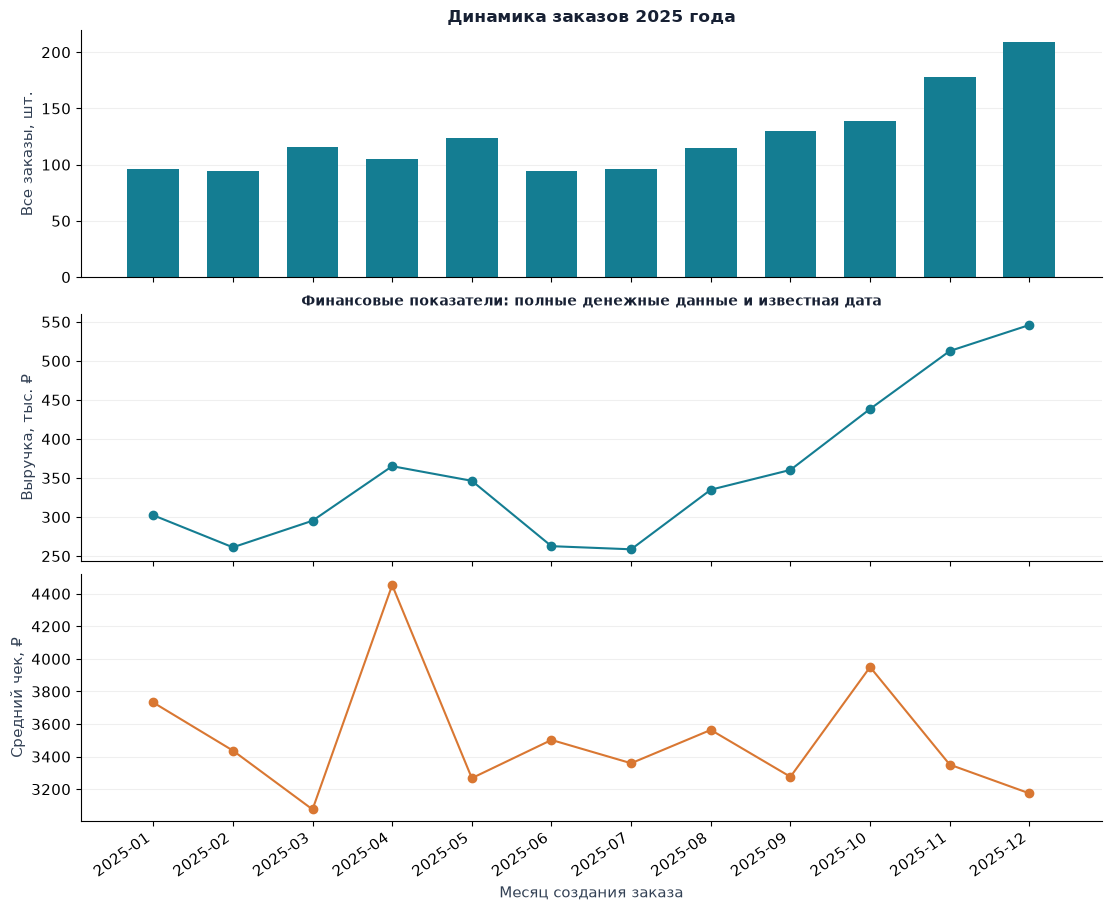

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, layout='constrained')
x = np.arange(len(monthly))
axes[0].bar(x, monthly['orders'], color='#147D92', width=0.65)
axes[0].set(title='Динамика заказов 2025 года', ylabel='Все заказы, шт.')
axes[1].plot(x, monthly['revenue_rub'].astype(float) / 1000, marker='o', color='#147D92')
axes[1].set(ylabel='Выручка, тыс. ₽')
axes[2].plot(x, monthly['average_order_rub'].astype(float), marker='o', color='#D97732')
axes[2].set(ylabel='Средний чек, ₽', xlabel='Месяц создания заказа')
axes[2].set_xticks(x, monthly.index.astype(str), rotation=35, ha='right')
for ax in axes:
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
axes[1].set_title('Финансовые показатели: полные денежные данные и известная дата', fontsize=10)
plt.show()


**Вывод.** Пик выручки по заказам с полной информацией и известной датой —
2025-12: 546 021,00 ₽,
минимум — 2025-07: 258 675,50 ₽.
Больше всего заказов создано в 2025-12 (209),
меньше всего — в 2025-02, 2025-06 (по 94).
Годовую сезонность по одному году установить нельзя: наблюдаемые колебания могут
зависеть от состава товаров, скидок и полноты данных. В помесячную выручку не попало
4 заказа на 12 222,00 ₽
из-за невозможных дат. Они остаются в общих денежных итогах.


### 4.3. Категории и товары

Чтобы не повторять одинаковые группировки, используем одну функцию для сегментов.
Число заказов и статусы считаем по всей таблице, денежные показатели — по `sales`.
Полнота данных показывает, какая доля доставленных заказов сегмента попала в расчёт денег.


In [15]:
def segment_summary(group_columns):
    counts = dt.groupby(group_columns, observed=True, dropna=False).agg(
        orders=('order_id', 'size'),
        delivered=('order_status', lambda s: s.eq('доставлен').sum()),
        cancelled=('order_status', lambda s: s.eq('отменён').sum()),
        returned=('order_status', lambda s: s.eq('возврат').sum()),
    )
    money = sales.groupby(group_columns, observed=True, dropna=False).agg(
        money_orders=('order_id', 'size'), revenue_rub=('revenue_rub', 'sum'),
        gross_profit_rub=('gross_profit_rub', 'sum'), quantity=('quantity', 'sum'),
    )
    result = counts.join(money)
    result['coverage_percent'] = result['money_orders'] / result['delivered'] * 100
    result['average_order_rub'] = result['revenue_rub'] / result['money_orders']
    result['gross_margin_percent'] = result['gross_profit_rub'] / result['revenue_rub'].where(result['revenue_rub'].ne(0)) * 100
    result['cancel_percent'] = result['cancelled'] / result['orders'] * 100
    result['return_percent'] = result['returned'] / (result['delivered'] + result['returned']).replace(0, np.nan) * 100
    return result

table_names = {
    'orders': 'Все заказы', 'delivered': 'Доставлено', 'cancelled': 'Отменено',
    'returned': 'Возвращено', 'money_orders': 'В денежной выборке',
    'revenue_rub': 'Выручка, ₽', 'gross_profit_rub': 'Валовая прибыль, ₽',
    'quantity': 'Продано единиц', 'coverage_percent': 'Полнота денег, %',
    'average_order_rub': 'Средний чек, ₽', 'gross_margin_percent': 'Рентабельность, %',
    'cancel_percent': 'Отмены, %', 'return_percent': 'Возвраты, %',
}
category_stats = segment_summary('category').sort_values('revenue_rub', ascending=False)
category_columns = ['orders', 'money_orders', 'coverage_percent', 'revenue_rub',
                    'gross_profit_rub', 'gross_margin_percent', 'average_order_rub']
display(category_stats[category_columns].rename(columns=table_names).round(2))


,Все заказы,В денежной выборке,"Полнота денег, %","Выручка, ₽","Валовая прибыль, ₽","Рентабельность, %","Средний чек, ₽"
category,,,,,,,
электроника,398,323,94.72,"2,182,414.00","780,404.00",35.76,"6,756.70"
аксессуары,367,294,93.93,"753,412.00","381,702.00",50.66,"2,562.63"
спорт,395,328,95.63,"693,822.50","352,092.50",50.75,"2,115.31"
товары для дома,340,292,95.42,"666,896.00","336,606.00",50.47,"2,283.89"


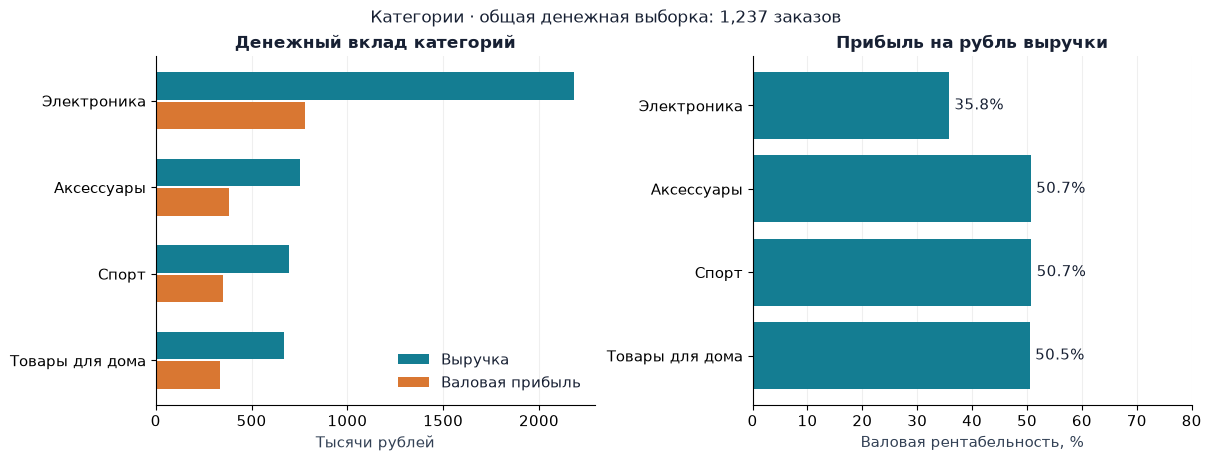

In [16]:
categories = category_stats.sort_values('revenue_rub')
positions = np.arange(len(categories))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
axes[0].barh(positions + 0.17, categories['revenue_rub'].astype(float) / 1000,
             height=0.32, label='Выручка', color='#147D92')
axes[0].barh(positions - 0.17, categories['gross_profit_rub'].astype(float) / 1000,
             height=0.32, label='Валовая прибыль', color='#D97732')
axes[0].set_yticks(positions, categories.index.str.capitalize())
axes[0].set(xlabel='Тысячи рублей', title='Денежный вклад категорий')
axes[0].legend(frameon=False, loc='lower right')
bars = axes[1].barh(positions, categories['gross_margin_percent'].astype(float), color='#147D92')
axes[1].set_yticks(positions, categories.index.str.capitalize())
axes[1].set(xlabel='Валовая рентабельность, %', title='Прибыль на рубль выручки', xlim=(0, 80))
axes[1].bar_label(bars, fmt='%.1f%%', padding=4)
for ax in axes:
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle(f'Категории · общая денежная выборка: {len(sales):,} заказов', fontsize=12)
plt.show()


,,В денежной выборке,"Выручка, ₽","Валовая прибыль, ₽","Рентабельность, %"
product_id,product_name,,,,
P003,Умные часы,90,"963,219.50","323,189.50",33.55
P001,Беспроводные наушники,66,"512,877.50","185,807.50",36.23
P002,Портативная колонка,70,"355,782.00","128,332.00",36.07
P004,Внешний аккумулятор,97,"350,535.00","143,075.00",40.82
P013,Рюкзак,69,"347,169.50","157,879.50",45.48
P011,Гантели 2 кг,76,"268,093.00","110,943.00",41.38
P005,Настольная лампа,84,"231,500.00","105,790.00",45.70
P009,Коврик для йоги,82,"209,239.00","114,169.00",54.56
P007,Плед,62,"185,697.50","92,697.50",49.92


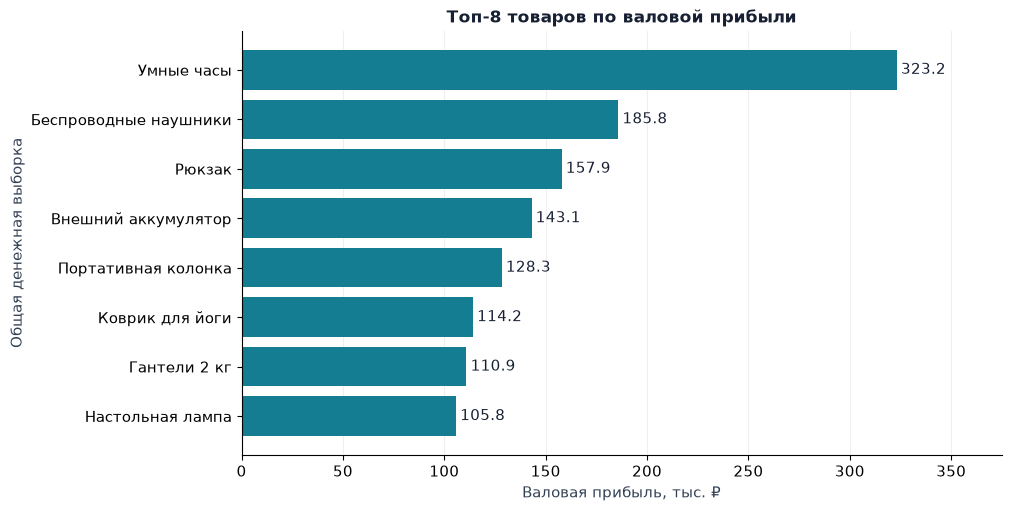

In [17]:
product_stats = segment_summary(['product_id', 'product_name']).sort_values('revenue_rub', ascending=False)
display(product_stats[['money_orders', 'revenue_rub', 'gross_profit_rub', 'gross_margin_percent']]
        .rename(columns=table_names).round(2))

top_products = product_stats.nlargest(8, 'gross_profit_rub').sort_values('gross_profit_rub')
fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
bars = ax.barh(top_products.index.get_level_values('product_name'),
               top_products['gross_profit_rub'].astype(float) / 1000, color='#147D92')
ax.bar_label(bars, fmt='%.1f', padding=3)
ax.margins(x=0.16)
ax.set(title='Топ-8 товаров по валовой прибыли', xlabel='Валовая прибыль, тыс. ₽',
       ylabel='Общая денежная выборка')
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
plt.show()


**Вывод.** Лидер по выручке — «электроника»:
2 182 414,00 ₽
(50,79% рассчитанной выручки).
По валовой прибыли лидирует «электроника» с 780 404,00 ₽,
а по рентабельности — «спорт» с 50,75%.
Поэтому объём денег и прибыльность на рубль выручки нужно оценивать отдельно.
У спорта, аксессуаров и товаров для дома рентабельность близка: 50,47–50,75%.
Небольшое различие само по себе не определяет приоритет закупок.

Среди товаров максимум выручки у «Умные часы»
(963 219,50 ₽), максимум валовой прибыли у
«Умные часы» (323 189,50 ₽),
максимум рентабельности у «Сумка-шоппер»
(64,11%,
n=72).
Это продажи в доступных данных, а не измерение потенциального спроса: запасов
и периодов отсутствия товара в наличии в файле нет.


### 4.4. Каналы привлечения

Доля отмен = отменённые / все заказы канала. Доля возвратов = возвращённые /
(доставленные + возвращённые) заказы канала. Это разные знаменатели.
Выручка и чек относятся к полной денежной выборке. В таблице видны размеры групп.
Расходов на продвижение нет, поэтому оценить стоимость привлечения и окупаемость каналов нельзя.


In [18]:
channel_stats = segment_summary('traffic_source').sort_values('orders', ascending=False)
display(channel_stats[['orders', 'delivered', 'returned', 'cancelled', 'money_orders',
                       'coverage_percent', 'average_order_rub', 'revenue_rub',
                       'gross_profit_rub', 'cancel_percent', 'return_percent']]
        .rename(columns=table_names).round(2))


,Все заказы,Доставлено,Возвращено,Отменено,В денежной выборке,"Полнота денег, %","Средний чек, ₽","Выручка, ₽","Валовая прибыль, ₽","Отмены, %","Возвраты, %"
traffic_source,,,,,,,,,,,
контекстная реклама,436,382,34,20,361,94.50,"3,287.65","1,186,841.00","520,661.00",4.59,8.17
органический поиск,431,376,37,18,359,95.48,"3,392.29","1,217,833.00","521,333.00",4.18,8.96
социальные сети,258,219,20,19,208,94.98,"3,424.18","712,228.50","310,148.50",7.36,8.37
прямой заход,255,216,24,15,202,93.52,"3,983.11","804,588.50","338,278.50",5.88,10.00
email,120,110,6,4,107,97.27,"3,505.17","375,053.50","160,383.50",3.33,5.17


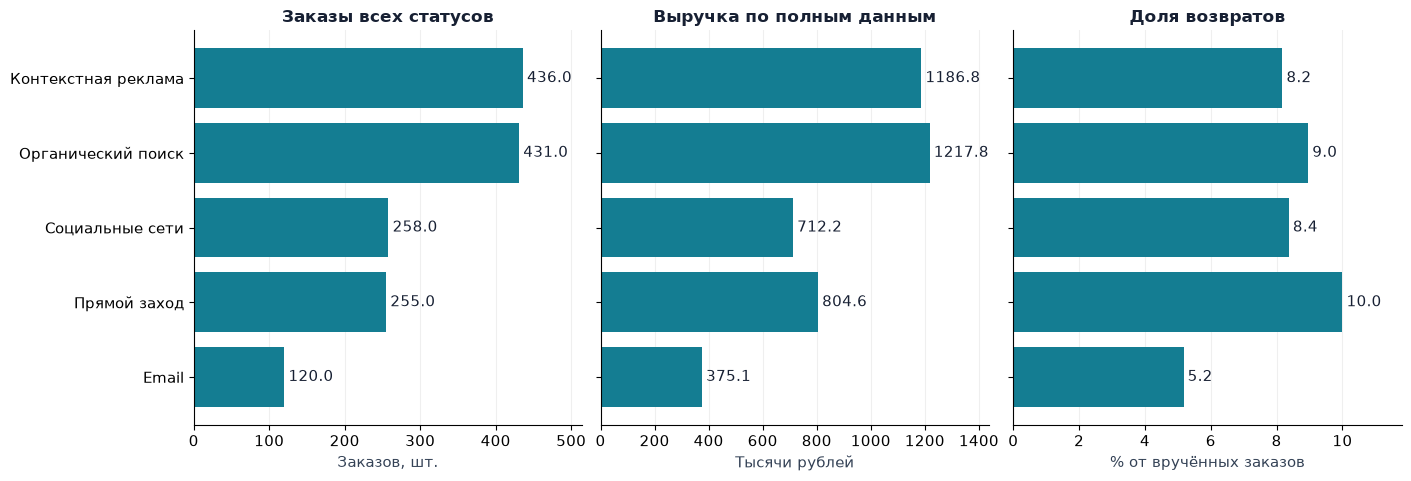

In [19]:
channels = channel_stats.sort_values('orders')
labels = channels.index.str.capitalize()
fig, axes = plt.subplots(1, 3, figsize=(14, 4.7), sharey=True, layout='constrained')
values = [channels['orders'], channels['revenue_rub'] / 1000, channels['return_percent']]
titles = ['Заказы всех статусов', 'Выручка по полным данным', 'Доля возвратов']
units = ['Заказов, шт.', 'Тысячи рублей', '% от вручённых заказов']
for ax, value, title, unit in zip(axes, values, titles, units):
    bars = ax.barh(labels, value.astype(float), color='#147D92')
    ax.bar_label(bars, fmt='%.1f', padding=3)
    ax.margins(x=0.18)
    ax.set(title=title, xlabel=unit)
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)
plt.show()


**Вывод.** Максимум рассчитанной выручки даёт «органический поиск»:
1 217 833,00 ₽ при
431 заказах всех статусов и
359 заказах в денежной выборке.
Самая высокая доля возвратов у «прямой заход» —
10,00%
(24 из
240 вручённых).
Для «email» она равна 5,17%.
Различия могут объясняться ассортиментом и составом покупателей. Оценки окупаемости
или решения о переносе рекламного бюджета без расходов на каналы здесь не обоснованы.


### 4.5. Скидки внутри категорий

Сравним группы скидки отдельно в каждой категории, используя общую денежную выборку.
Интервалы: 0%, (0; 5]%, (5; 10]%, (10; 15]% и (15; 100]%.
Вместе с чеком и рентабельностью покажем число заказов и среднее количество единиц.
Даже внутри категории различается состав товаров: это описательное сравнение,
которое не доказывает влияние скидки на спрос.


Все заказы  Среднее количество  \
category        discount_group                                   
аксессуары      Без скидки             122                1.41   
                До 5%                   42                1.64   
                5–10%                   47                1.64   
                10–15%                  34                1.59   
                Свыше 15%               49                1.65   
спорт           Без скидки             139                1.45   
                До 5%                   42                1.50   
                5–10%                   55                1.44   
                10–15%                  41                1.49   
                Свыше 15%               51                1.51   
товары для дома Без скидки             136                1.74   
                До 5%                   30                1.33   
                5–10%                   45                1.31   
                10–15%                  40                1.55   
                Свыше 15%               41                1.51   
электроника     Без скидки             138                1.64   
                До 5%                   39                1.79   
                5–10%                   51                1.39   
                10–15%                  45                1.44   
                Свыше 15%               50                1.80   

                                Средний чек, ₽  Рентабельность, %  
category        discount_group                                     
аксессуары      Без скидки            2,507.38              54.91  
                До 5%                 2,980.29              51.49  
                5–10%                 2,799.38              49.53  
                10–15%                2,227.00              47.44  
                Свыше 15%             2,347.98              41.88  
спорт           Без скидки            2,429.50              52.98  
                До 5%                 2,251.73              52.84  
                5–10%                 1,844.51              49.74  
                10–15%                1,859.01              46.97  
                Свыше 15%             1,644.75              44.05  
товары для дома Без скидки            2,584.41              54.42  
                До 5%                 1,945.92              51.56  
                5–10%                 1,950.00              48.26  
                10–15%                2,061.46              46.13  
                Свыше 15%             2,117.80              40.14  
электроника     Без скидки            7,747.17              39.77  
                До 5%                 7,798.53              36.66  
                5–10%                 5,905.76              33.15  
                10–15%                5,193.50              31.33  
                Свыше 15%             5,485.20              25.76

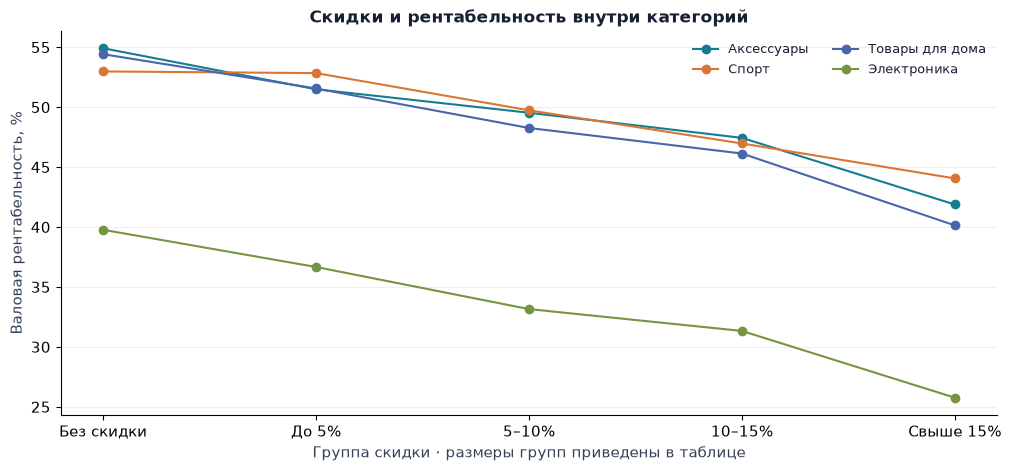

In [20]:
discount_labels = ['Без скидки', 'До 5%', '5–10%', '10–15%', 'Свыше 15%']
discount_sales = sales.copy()
discount_sales['discount_group'] = pd.cut(
    discount_sales['discount_percent'].astype(float),
    bins=[-0.001, 0, 5, 10, 15, 100], labels=discount_labels,
)
discount_stats = discount_sales.groupby(['category', 'discount_group'], observed=True).agg(
    orders=('order_id', 'size'), revenue_rub=('revenue_rub', 'sum'),
    gross_profit_rub=('gross_profit_rub', 'sum'), average_quantity=('quantity', 'mean'),
)
discount_stats['average_order_rub'] = discount_stats['revenue_rub'] / discount_stats['orders']
discount_stats['gross_margin_percent'] = (
    discount_stats['gross_profit_rub'] / discount_stats['revenue_rub'].where(discount_stats['revenue_rub'].ne(0)) * 100
)
display(discount_stats[['orders', 'average_quantity', 'average_order_rub', 'gross_margin_percent']]
        .rename(columns={**table_names, 'average_quantity': 'Среднее количество'}).round(2))

margin_by_discount = discount_stats['gross_margin_percent'].unstack('category').reindex(discount_labels)
fig, ax = plt.subplots(figsize=(10, 4.6), layout='constrained')
for category in margin_by_discount.columns:
    ax.plot(discount_labels, margin_by_discount[category].astype(float), marker='o', label=category.capitalize())
ax.set(title='Скидки и рентабельность внутри категорий',
       xlabel='Группа скидки · размеры групп приведены в таблице', ylabel='Валовая рентабельность, %')
ax.legend(frameon=False, ncol=2, fontsize=9)
ax.grid(axis='y', alpha=0.2)
plt.show()


**Вывод.** Для категории «электроника» рентабельность составляет 39,77% без скидки (n=138) и 25,76% при скидке свыше 15% (n=50).

Для категории «аксессуары» рентабельность составляет 54,91% без скидки (n=122) и 41,88% при скидке свыше 15% (n=49).

Для категории «спорт» рентабельность составляет 52,98% без скидки (n=139) и 44,05% при скидке свыше 15% (n=51).

Для категории «товары для дома» рентабельность составляет 54,42% без скидки (n=136) и 40,14% при скидке свыше 15% (n=41).

В этих группах скидка свыше 15% связана с меньшей рентабельностью. При прочих равных скидка снижает выручку при той же закупочной себестоимости. Но наблюдаемые чеки также зависят от товара и количества единиц. Без эксперимента и данных о спросе нельзя заключить, что скидки увеличили продажи или стали причиной различий между группами.


### 4.6. Доставка и оценки

Для сроков используем доставленные и впоследствии возвращённые заказы с известным
положительным сроком до первоначального вручения. Для связи срока и оценки берём
только статус «доставлен» и две известные допустимые величины: так не смешиваются статусы.
Рассчитаем ранговую корреляцию Спирмена, поскольку оценка — порядковая шкала 1–5.
Порог «больше 7 дней» — описательная группа, обещанного срока доставки в данных нет.


In [21]:
delivery_orders = dt.loc[
    dt['order_status'].isin(['доставлен', 'возврат']) & dt['delivery_days'].notna()
].copy()
city_delivery = delivery_orders.groupby('city').agg(
    orders=('order_id', 'size'), mean_days=('delivery_days', 'mean'),
    median_days=('delivery_days', 'median'), over_7=('delivery_days', lambda s: s.gt(7).sum()),
)
city_delivery['over_7_percent'] = city_delivery['over_7'] / city_delivery['orders'] * 100
city_delivery = city_delivery.sort_values('mean_days', ascending=False)
display(city_delivery.rename(columns={
    'orders': 'Известных сроков', 'mean_days': 'Среднее, дней', 'median_days': 'Медиана, дней',
    'over_7': 'Больше 7 дней, заказов', 'over_7_percent': 'Больше 7 дней, %',
}).round(2))

rating_pairs = dt.loc[
    delivered & dt['delivery_days'].notna() & dt['customer_rating'].notna()
].copy()
rho = rating_pairs[['delivery_days', 'customer_rating']].astype(float).corr(method='spearman').iloc[0, 1]
rating_pairs['delivery_group'] = pd.cut(
    rating_pairs['delivery_days'].astype(float), bins=[0, 2, 4, 6, np.inf],
    labels=['1–2 дня', '3–4 дня', '5–6 дней', '7+ дней'],
)
rating_by_delivery = rating_pairs.groupby('delivery_group', observed=True).agg(
    orders=('order_id', 'size'), mean_rating=('customer_rating', 'mean'),
)
display(rating_by_delivery.rename(columns={'orders': 'Заказов с оценкой', 'mean_rating': 'Средняя оценка'}).round(2))
print(f'Корреляция Спирмена: {rho:.3f}; пар значений: {len(rating_pairs)}')
print('Неизвестен срок у вручённых заказов:',
      dt.loc[dt.order_status.isin(['доставлен', 'возврат']), 'delivery_days'].isna().sum())
print('Нет допустимой оценки у доставленных:', dt.loc[delivered, 'customer_rating'].isna().sum())


,Известных сроков,"Среднее, дней","Медиана, дней","Больше 7 дней, заказов","Больше 7 дней, %"
city,,,,,
Новосибирск,115,5.25,5.00,15,13.04
Казань,247,5.22,5.00,23,9.31
Екатеринбург,167,5.10,5.00,12,7.19
Краснодар,128,5.05,5.00,10,7.81
Город неизвестен,35,4.49,5.00,2,5.71
Санкт-Петербург,308,4.22,4.00,19,6.17
Москва,395,3.04,3.00,7,1.77


,Заказов с оценкой,Средняя оценка
delivery_group,,
1–2 дня,149,4.34
3–4 дня,374,4.12
5–6 дней,314,4.26
7+ дней,95,3.65


Корреляция Спирмена: -0.104; пар значений: 932
Неизвестен срок у вручённых заказов: 29
Нет допустимой оценки у доставленных: 349


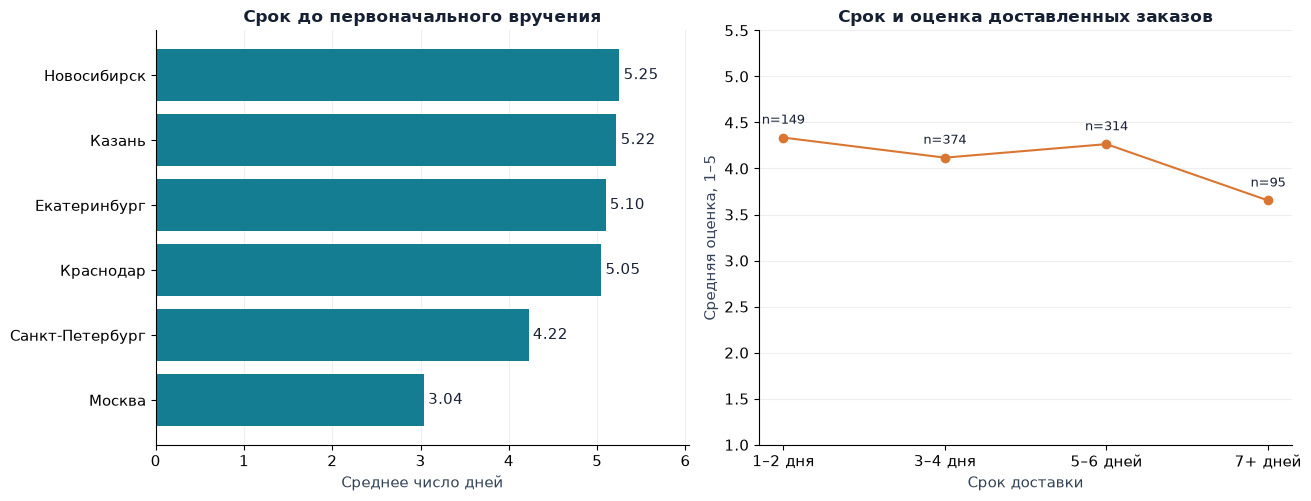

In [22]:
known_cities = city_delivery.drop(index='Город неизвестен', errors='ignore').sort_values('mean_days')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.9), layout='constrained')
bars = axes[0].barh(known_cities.index, known_cities['mean_days'].astype(float), color='#147D92')
axes[0].bar_label(bars, fmt='%.2f', padding=3)
axes[0].margins(x=0.15)
axes[0].set(title='Срок до первоначального вручения', xlabel='Среднее число дней')
score_values = rating_by_delivery['mean_rating'].astype(float)
axes[1].plot(rating_by_delivery.index.astype(str), score_values, marker='o', color='#D97732')
for i, (value, n) in enumerate(zip(score_values, rating_by_delivery['orders'])):
    axes[1].annotate(f'n={n}', (i, value), xytext=(0, 10), textcoords='offset points', ha='center', fontsize=9)
axes[1].set(title='Срок и оценка доставленных заказов', xlabel='Срок доставки',
            ylabel='Средняя оценка, 1–5', ylim=(1, 5.5))
for ax in axes:
    ax.grid(axis='x' if ax is axes[0] else 'y', alpha=0.2)
    ax.set_axisbelow(True)
plt.show()


**Вывод.** Среди известных городов самый большой средний срок в городе
Новосибирск: 5,25 дня
(n=115), самый короткий — Москва:
3,04 дня (n=395).
В городе Новосибирск доля сроков больше 7 дней составляет
13,04%.

Для 932 доставленных заказов с двумя известными значениями
корреляция Спирмена равна -0,104: связь слабая отрицательная.
Средняя оценка при сроке 1–2 дня —
4,34 (n=149),
при сроке 7+ дней — 3,65
(n=95). Связь описывает наблюдения и не устанавливает
причину: отзывы оставляют не все, а состав товаров и покупателей может различаться.


### 4.7. Повторные покупки

Рассмотрим покупателей с хотя бы одним доставленным заказом с подтверждённой датой
в 2025 году. Повторный покупатель имеет два и более таких заказа. Неполная денежная
запись учитывается при определении повторности. Чек сравниваем только по полной
денежной выборке с известной датой. Заказы с неизвестной датой исключены из этой части.


In [23]:
delivered_year = dt.loc[delivered & dt['order_date'].notna()].copy()
buyer_order_counts = delivered_year.groupby('customer_id')['order_id'].size()
repeat_share = buyer_order_counts.ge(2).mean() * 100
buyer_groups = buyer_order_counts.ge(2).map({False: 'Одна покупка', True: 'Повторные покупки'})

delivered_year['buyer_group'] = delivered_year['customer_id'].map(buyer_groups)
buyer_money = dated_sales.copy()
buyer_money['buyer_group'] = buyer_money['customer_id'].map(buyer_groups)
buyer_stats = delivered_year.groupby('buyer_group').agg(
    customers=('customer_id', 'nunique'), delivered_orders=('order_id', 'size'),
).join(buyer_money.groupby('buyer_group').agg(
    money_orders=('order_id', 'size'), revenue_rub=('revenue_rub', 'sum'),
))
buyer_stats['average_order_rub'] = buyer_stats['revenue_rub'] / buyer_stats['money_orders']
display(buyer_stats.rename(columns={
    **table_names, 'customers': 'Покупателей', 'delivered_orders': 'Доставленных заказов',
}).round(2))
print(f'Доля повторных покупателей: {repeat_share:.2f}% '
      f'({buyer_order_counts.ge(2).sum()} из {len(buyer_order_counts)})')


,Покупателей,Доставленных заказов,В денежной выборке,"Выручка, ₽","Средний чек, ₽"
buyer_group,,,,,
Одна покупка,52,52,49,"221,252.00","4,515.35"
Повторные покупки,325,1247,1184,"4,063,070.50","3,431.65"


Доля повторных покупателей: 86.21% (325 из 377)


**Вывод.** Среди 377 покупателей с подтверждёнными
доставленными заказами в 2025 году повторные покупки совершили
325, или **86,21%**.
Средний чек по полной денежной информации для группы с одной покупкой —
4 515,35 ₽,
для группы с повторными — 3 431,65 ₽.
Это повторность внутри одного года, а не удержание и не доля новых клиентов:
покупки до 2025 года неизвестны, а у покупателей конца года меньше времени на повтор.


**Вывод по анализу.** В денежной выборке выручка составляет 4 296 544,50 ₽
при рентабельности 43,08%. Сравнены месяцы, категории, товары и каналы,
отдельно рассмотрены скидки, доставка и повторные покупки. Лидерство по обороту
не гарантирует максимальную рентабельность. Результаты дают основания для проверок
ассортимента и процессов, но не для причинных выводов или оценки рекламной окупаемости.


## 5. Оформление результатов
### Проверка согласованности расчётов

Проверим, что разрезы не теряют деньги и не дублируют заказы, а сумма по месяцам
отличается от общего итога только на заказы с неизвестной датой.


In [24]:
assert int(status_counts.sum()) == len(dt)
assert len(sales) + excluded_money == int(delivered.sum())
assert np.isclose(float(revenue - sales['cogs_rub'].sum()), float(profit))
assert np.isclose(float(category_stats['revenue_rub'].sum()), float(revenue))
assert np.isclose(float(product_stats['revenue_rub'].sum()), float(revenue))
assert np.isclose(float(channel_stats['revenue_rub'].sum()), float(revenue))
assert np.isclose(float(monthly['revenue_rub'].sum() + undated_sales['revenue_rub'].sum()), float(revenue))
assert int(monthly['orders'].sum() + len(date_problems)) == len(dt)
assert dt.loc[no_sale, money_cols].eq(0).all().all()
assert dt_raw.equals(pd.read_csv(data_path, encoding='utf-8-sig'))
print('Проверки согласованности пройдены. Исходная таблица сохранена без изменений.')


Проверки согласованности пройдены. Исходная таблица сохранена без изменений.


### Итоги и три рекомендации

1. **Проверить доступность товаров, которые дают наибольшую валовую прибыль.**
   Категория «электроника» даёт 780 404,00 ₽ валовой
   прибыли, а товар «Умные часы» — 323 189,50 ₽.
   У спорта, аксессуаров и товаров для дома рентабельность близка (50,47–50,75%),
   поэтому приоритет закупок в этих категориях нужно уточнить по спросу и запасам.
   Следующий шаг — проверить остатки и периоды отсутствия лидеров, затем провести
   ограниченный тест доступности. Нужны история запасов, закупочные ограничения,
   сроки поставщиков и логистические расходы. Критерий проверки — изменение валовой
   прибыли и числа дней отсутствия товара без непропорционального роста запасов.

2. **Разобрать причины возвратов заказов из канала «прямой заход».**
   Доля возвратов — 10,00%
   (24 из
   240 вручённых),
   у канала «email» — 5,17%.
   Сначала сравнить одинаковые товары, города и периоды, проверить карточки товаров
   и корректность атрибуции прямых заходов. Нужны причины возврата, источники переходов,
   UTM-метки, расходы и затраты на обратную доставку. Проверять снижение возвратов
   при сопоставимом составе заказов. Решение о рекламном бюджете принимать после
   оценки затрат, а не только по обороту.

3. **Проверить маршруты и работу перевозчиков в городе Новосибирск.**
   Средний срок — 5,25 дня против
   3,04 дня в городе Москва.
   Срок больше 7 дней встречается у 13,04% заказов
   с известной доставкой в этом городе. Связь срока с оценкой слабая отрицательная
   (Спирмен -0,104). Нужны обещанные и фактические даты, этапы доставки,
   перевозчик и стоимость маршрута. Провести пилот на сопоставимых заказах и
   проверить срок, долю нарушений обещанного срока, оценки и стоимость доставки.

### Ограничения

- Данные синтетические. Рекомендации показывают метод анализа учебного магазина
  и требуют проверки на реальных операционных данных.
- Денежные итоги рассчитаны по 1 237 из 1 303
  доставленных заказов. Для 66 заказов не хватает допустимых
  исходных значений. Пропуски могут быть неслучайными и смещать сравнения.
- Четыре даты неизвестны после проверки. Соответствующие заказы сохранены в общих
  итогах, но исключены из динамики и определения повторных покупок за год.
- Нет рекламных, логистических, налоговых и прочих расходов. Валовая прибыль
  не является чистой, окупаемость каналов и полную экономику возвратов рассчитать нельзя.
- Один год не подтверждает сезонность. Нет истории клиентов до 2025 года,
  обещанных сроков доставки и сведений о покупателях, не оставивших отзыв.
- Связи скидки и продаж, доставки и оценки описательные. Причинные эффекты
  требуют эксперимента или отдельного исследования.

**Вывод по проекту.** Данные проверены и подготовлены, ключевые показатели и семь
исследовательских вопросов разобраны. Для следующего шага предложены три проверяемые
рекомендации с измеримыми критериями и перечнем дополнительных данных.
